In [1]:
import numpy as np 
import pandas as pd 
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt 
import seaborn as sns



Bad value in file WindowsPath('C:/Users/bhard/anaconda3/Lib/site-packages/matplotlib/mpl-data/stylelib/classic.mplstyle'), line 162 ('mathtext.default: normal  # The default font to use for math.'): Key mathtext.default: 'normal' is not a valid value for mathtext.default; supported values are ['rm', 'cal', 'bfit', 'it', 'tt', 'sf', 'bf', 'default', 'bb', 'frak', 'scr', 'regular']

Bad key axes3d.depthshade in file C:\Users\bhard\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle, line 225 ('axes3d.depthshade   : False   # depth shade for 3D scatter plots')
You probably need to get an updated matplotlibrc file from
https://github.com/matplotlib/matplotlib/blob/v3.10.0/lib/matplotlib/mpl-data/matplotlibrc
or from the matplotlib source distribution

Bad key axes3d.depthshade_minalpha in file C:\Users\bhard\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle, line 226 ('axes3d.depthshade_minalpha : 0.3  # minimum alpha value for depth shading')


In [2]:
df = pd.read_csv('train.csv',usecols=['Age','Fare','Survived'])

In [3]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [5]:
df.isnull().mean()*100

Survived     0.00000
Age         19.86532
Fare         0.00000
dtype: float64

In [6]:
x = df.drop(columns=["Survived"])
y = df['Survived']

In [7]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [9]:
x_train['age_imputed'] = x_train['Age']
x_test['age_imputed'] = x_test['Age']

In [29]:
x_test.head()

,Age,Fare,age_imputed
709,NaN,15.2458,NaN
439,31.0,10.5000,31.0
840,20.0,7.9250,20.0
720,6.0,33.0000,6.0
39,14.0,11.2417,14.0


In [36]:
 x_train['Age'].dropna().sample(x_test['Age'].isnull().sum()).values

array([25. , 26. , 29. , 60. , 70. , 16. ,  1. , 58. , 13. , 22. , 28. ,
       50. , 41. , 25. , 21. , 33. , 18. , 35. , 36.5, 28. , 31. , 19. ,
       25. ,  1. , 33. , 34. ,  4. , 45. , 19. , 56. , 44. , 19. ,  9. ,
       56. , 38. , 17. , 26. ])

In [43]:
train_mask = x_train['age_imputed'].isnull()
x_train.loc[train_mask, 'age_imputed'] = (
    x_train['Age'].dropna().sample(train_mask.sum(), random_state=42).values
)

# 2. Fix test data (sampling from train set to avoid data leakage)
test_mask = x_test['age_imputed'].isnull()
x_test.loc[test_mask, 'age_imputed'] = (
    x_train['Age'].dropna().sample(test_mask.sum(), random_state=42).values
)

In [46]:
x_train

,Age,Fare,age_imputed
331,45.5,28.5000,45.5
733,23.0,13.0000,23.0
382,32.0,7.9250,32.0
704,26.0,7.8542,26.0
813,6.0,31.2750,6.0
...,...,...,...
106,21.0,7.6500,21.0
270,NaN,31.0000,35.0
860,41.0,14.1083,41.0
435,14.0,120.0000,14.0


<Axes: ylabel='Density'>

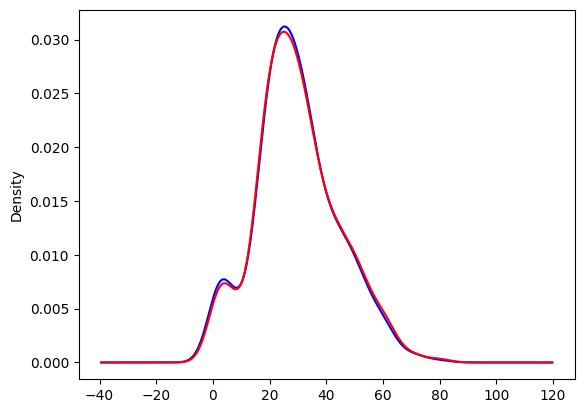

In [48]:
fig =plt.figure()
ax = fig.add_subplot(111)
x_train['Age'].plot(kind='kde',ax=ax,color='blue')

x_train['age_imputed'].plot(kind='kde',ax=ax,color='red')

<Axes: xlabel='Age', ylabel='Count'>

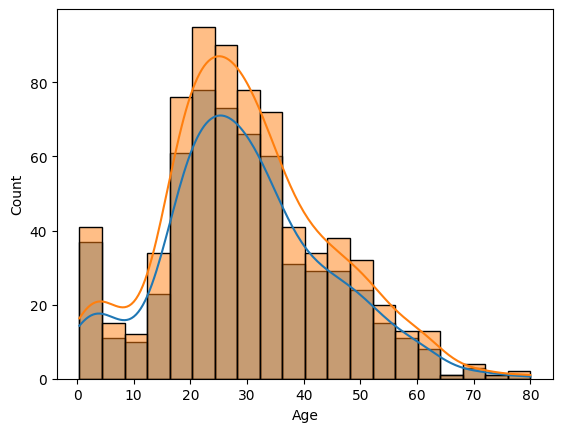

In [49]:
sns.histplot(x_train['Age'],label='original',kde=True)
sns.histplot(x_train['age_imputed'],label='imputed',kde=True)

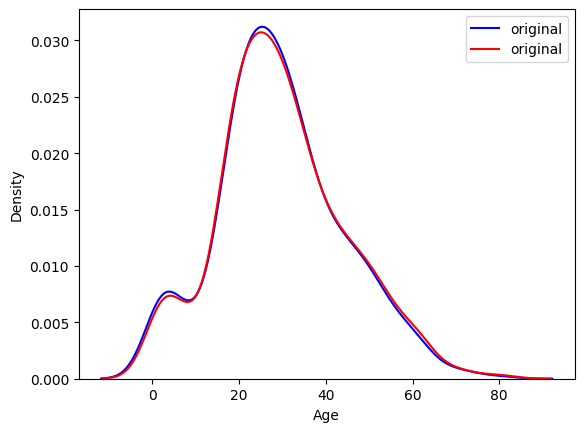

In [50]:
fig =plt.figure()
ax = fig.add_subplot(111)
sns.kdeplot(data=x_train['Age'], ax = ax ,color='blue', label = 'original')
sns.kdeplot(data=x_train['age_imputed'], ax = ax ,color='red', label = 'original')
ax.legend()
plt.show()

In [52]:
print('original variable variance ',x_train['Age'].var())
print('variance after random imputation',x_train['age_imputed'].var())

original variable variance  210.2517072477438
variance after random imputation 215.0725265394129


In [58]:
x_train[['Fare','Age','age_imputed']].cov()

,Fare,Age,age_imputed
Fare,2700.831981,71.580633,57.302910
Age,71.580633,210.251707,210.251707
age_imputed,57.302910,210.251707,215.072527


<Axes: >

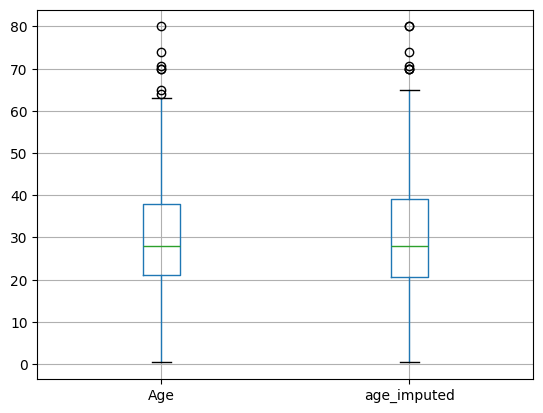

In [59]:
x_train[['Age','age_imputed']].boxplot()

In [62]:
sampled_value = x_train['Age'].dropna().sample(1,random_state=int(observation['Fare']))

NameError: name 'observation' is not defined

In [63]:
data = pd.read_csv('house-train.csv',usecols=['GarageQual','FireplaceQu','SalePrice'])

In [64]:
data.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [65]:
data.isnull().mean()*100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

In [67]:
x = data 
y = data['SalePrice']

In [68]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [70]:
x_train['GarageQual_imputed'] =x_train['GarageQual']
x_test['GarageQual_imputed'] =x_test['GarageQual']

x_train['FireplaceQu_imputed'] =x_train['FireplaceQu']
x_test['FireplaceQu_imputed'] =x_test['FireplaceQu']


In [72]:
x_train.sample(5)

,FireplaceQu,GarageQual,SalePrice,GarageQual_imputed,FireplaceQu_imputed
888,TA,TA,268000,TA,TA
1423,Gd,Gd,274970,Gd,Gd
17,NaN,TA,90000,TA,NaN
1242,TA,TA,170000,TA,TA
470,NaN,TA,212000,TA,NaN


In [73]:
train_mask = x_train['GarageQual_imputed'].isnull()
x_train.loc[train_mask, 'GarageQual_imputed'] = (
    x_train['GarageQual'].dropna().sample(train_mask.sum(), random_state=42).values
)

# 2. Fix test data (sampling from train set to avoid data leakage)
test_mask = x_test['GarageQual_imputed'].isnull()
x_test.loc[test_mask, 'GarageQual_imputed'] = (
    x_train['GarageQual'].dropna().sample(test_mask.sum(), random_state=42).values
)



fire_mask = x_train['FireplaceQu_imputed'].isnull()
x_train.loc[fire_mask, 'FireplaceQu_imputed'] = (
    x_train['FireplaceQu'].dropna().sample(fire_mask.sum(), random_state=42).values
)

# 2. Fix test data (sampling from train set to avoid data leakage)
firet_mask = x_test['FireplaceQu_imputed'].isnull()
x_test.loc[firet_mask, 'FireplaceQu_imputed'] = (
    x_train['FireplaceQu'].dropna().sample(firet_mask.sum(), random_state=42).values
)

In [76]:
temp = pd.concat([
    x_train['GarageQual'].value_counts()/len(x_train['GarageQual'].dropna()),
    x_train['GarageQual_imputed'].value_counts()/len(x_train)
],axis=1)
temp.columns = ['original','imputed']

In [77]:
temp

,original,imputed
TA,0.951087,0.951199
Fa,0.032609,0.031678
Gd,0.011775,0.012842
Ex,0.002717,0.002568
Po,0.001812,0.001712


In [78]:
temp = pd.concat([
    x_train['FireplaceQu'].value_counts()/len(x_train['FireplaceQu'].dropna()),
    x_train['FireplaceQu_imputed'].value_counts()/len(x_train)
],axis=1)
temp.columns = ['original','imputed']

In [79]:
temp

,original,imputed
Gd,0.491143,0.499144
TA,0.405797,0.401541
Fa,0.043478,0.042808
Ex,0.033816,0.032534
Po,0.025765,0.023973


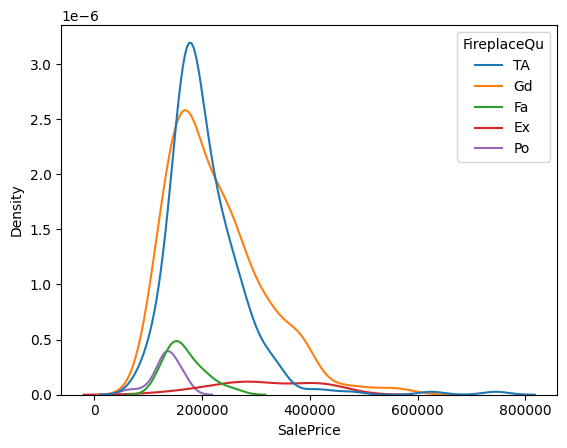

In [81]:
# Clean, single-line alternative to the entire for loop
sns.kdeplot(data=x_train, x='SalePrice', hue='FireplaceQu')

plt.show()

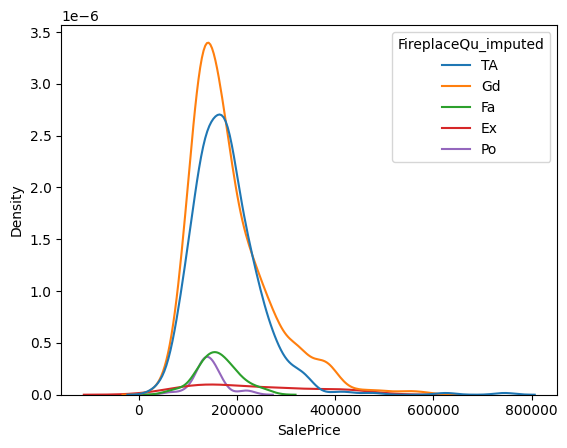

In [83]:
# Clean, single-line alternative to the entire for loop
sns.kdeplot(data=x_train, x='SalePrice', hue='FireplaceQu_imputed')

plt.show()